In [157]:
import pickle
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

import sys
sys.path.append('..')
from cirr.models.forecaster import Forecaster

In [165]:
checkpoint_path = '../checkpoints/epoch_005.ckpt'
model = Forecaster.load_from_checkpoint(checkpoint_path)

/home/mateusz/miniconda3/envs/cirr/lib/python3.11/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


In [166]:
periods_path = Path('../data/Modena/modena_periods_4_5_15.pkl')

with open(periods_path, 'rb') as f:
    periods = pickle.load(f)

In [167]:
periods[0]

{'history': [{'image_name': '/home/mateusz/Research/continual-solar-irradiance/data/Modena/images/2024_06_06__18_52_00_rpi_hq_imx477r_fisheye_rgb_camera.jpg',
   'irradiance': 114.08},
  {'image_name': '/home/mateusz/Research/continual-solar-irradiance/data/Modena/images/2024_06_06__18_57_00_rpi_hq_imx477r_fisheye_rgb_camera.jpg',
   'irradiance': 71.55},
  {'image_name': '/home/mateusz/Research/continual-solar-irradiance/data/Modena/images/2024_06_06__19_02_00_rpi_hq_imx477r_fisheye_rgb_camera.jpg',
   'irradiance': 76.28},
  {'image_name': '/home/mateusz/Research/continual-solar-irradiance/data/Modena/images/2024_06_06__19_07_00_rpi_hq_imx477r_fisheye_rgb_camera.jpg',
   'irradiance': 70.49}],
 'target_irradiance': 55.39}

In [168]:
IMG_MEAN = [ 0.485, 0.456, 0.406 ]
IMG_STD = [ 0.229, 0.224, 0.225 ]

CROP_MASK = cv2.circle(
    np.zeros((128, 128, 3), dtype=np.uint8),
    (128 // 2, 128 // 2),
    128 // 2,
    color=(1, 1, 1),
    thickness=-1,
)


def preprocess_input(period):
    image_path = period['history'][-1]['image_name']
    irradiance_history = [item['irradiance'] for item in period['history']]
    target_irradiance = period['target_irradiance']

    img = np.asarray(Image.open(image_path).convert('RGB'))[:, 254:-254]
    img = cv2.resize(img, (128, 128)) / 255.0
    img = (img - IMG_MEAN ) / IMG_STD
    img = np.where(CROP_MASK, img, 0.).astype(np.float32)

    img_tensor = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
    irradiance_history_tensor = torch.tensor(irradiance_history, dtype=torch.float32)
    target_irradiance = torch.tensor(target_irradiance, dtype=torch.float32)

    return img_tensor, irradiance_history_tensor, target_irradiance

In [169]:
raw_outputs = []
target_irradiances = []

for period in tqdm(periods):
    img_tensor, irradiance_history_tensor, target_irradiance = preprocess_input(period)

    output = model(img_tensor.unsqueeze(0), irradiance_history_tensor.unsqueeze(0))
    output, target_irradiance

    raw_outputs.append(output.squeeze().detach().numpy().tolist())
    target_irradiances.append(target_irradiance)

  4%|▍         | 381/9420 [01:16<30:14,  4.98it/s]


KeyboardInterrupt: 

In [ ]:
np.save(f'{periods_path.parent.lower()}_raw_output.npy', raw_outputs)

In [ ]:
rmse = root_mean_squared_error(y_true=target_irradiances, y_pred=raw_outputs)
mae = mean_absolute_error(y_true=target_irradiances, y_pred=raw_outputs)
mape = mean_absolute_percentage_error(y_true=target_irradiances, y_pred=raw_outputs)

In [159]:
rmse, mae, mape

(125.33980204715142, 78.85741703546933, 3.651597095921775e+16)

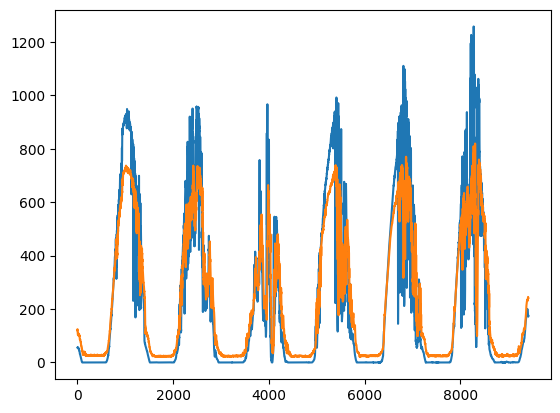

In [ ]:
plt.plot(target_irradiances)
plt.plot(raw_outputs)

In [164]:
# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

model.train()
optimizer.zero_grad()

num_periods = len(periods)

# Training loop
for idx, period in enumerate(tqdm(periods)):
    img_tensor, irradiance_history_tensor, target_irradiance = preprocess_input(period)

    output = model(img_tensor.unsqueeze(0), irradiance_history_tensor.unsqueeze(0))
    
    # Forward pass
    outputs = model(img_tensor.unsqueeze(0), irradiance_history_tensor.unsqueeze(0))
    
    # Calculate loss
    loss = criterion(outputs, target_irradiance)
    
    # Calculate percentage difference
    percentage_diff = torch.abs((outputs - target_irradiance) / target_irradiance)
    
    # Mask for values greater than 15%
    if percentage_diff > 0.15:
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        print(f'Period [{idx+1}/{num_periods}], target: {target_irradiance.item():.4f}, output: {outputs.item():.4f}, loss: {loss.item():.4f}')
    else:
        print(f'Period [{idx+1}/{num_periods}] in range, target: {target_irradiance.item():.4f}, output: {outputs.item():.4f}, loss: {loss.item():.4f}')

  0%|          | 1/9420 [00:01<2:42:09,  1.03s/it]

Period [1/9420], target: 55.3900, output: 36.0569, loss: 373.7684


  0%|          | 2/9420 [00:01<2:24:25,  1.09it/s]

Period [2/9420], target: 54.9800, output: 80.7224, loss: 662.6702


  0%|          | 3/9420 [00:02<2:23:38,  1.09it/s]

...

Period [61/9420], target: 26.9100, output: 22.4817, loss: 19.6102


  1%|          | 62/9420 [00:26<2:07:33,  1.22it/s]

Period [62/9420], target: 26.1000, output: 10.5482, loss: 241.8595


  1%|          | 62/9420 [00:27<1:09:02,  2.26it/s]


KeyboardInterrupt: 

In [ ]:
# Sample data
inputs = torch.randn(25, 3)
targets = torch.randn(25, 1)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop with delayed action
num_epochs = 100
delay = 15
stored_gradients = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    
    for i in range(len(inputs)):
        # Forward pass
        output = model(inputs[i].unsqueeze(0))
        
        # Calculate loss
        loss = criterion(output, targets[i].unsqueeze(0))
        
        # Backward pass
        loss.backward()
        
        # Store gradients
        stored_gradients.append([param.grad.clone() for param in model.parameters()])
        
        # Apply delayed gradients
        if len(stored_gradients) > delay:
            delayed_grads = stored_gradients.pop(0)
            for param, delayed_grad in zip(model.parameters(), delayed_grads):
                if param.grad is not None:
                    param.grad += delayed_grad
                else:
                    param.grad = delayed_grad
        
        # Update weights
        optimizer.step()
        optimizer.zero_grad()
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')